# Iris Flower Species Classification
### A Simple Machine Learning Mini Project

**Internship:** Artificial Intelligence and Machine Learning — EasyShiksha
**Tools Used:** Python, Jupyter Notebook, scikit-learn, pandas, matplotlib, seaborn

---

**Objective:** Build a simple machine learning model that classifies an Iris flower
into one of three species — *Setosa*, *Versicolor*, or *Virginica* — based on
four measurements: sepal length, sepal width, petal length, and petal width.

This is a classic beginner-friendly ML project that covers the full workflow:
loading data, exploring it, training a model, evaluating it, and making a
prediction on new data.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_style("whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2: Load the Dataset

We use the classic **Iris dataset**, which is built into scikit-learn. It
contains 150 samples of iris flowers with 4 features each, and a target
label indicating the species.

In [ ]:

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Step 3: Explore the Data

Before building a model, it's good practice to understand the data —
check for missing values, look at basic statistics, and see how many
samples belong to each species.

In [ ]:

print("Missing values per column:")
print(df.isnull().sum())

print("\nNumber of samples per species:")
print(df['species'].value_counts())

Missing values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Number of samples per species:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [ ]:

df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## Step 4: Visualize the Data

A scatter plot of petal length vs petal width already shows the three
species form fairly distinct clusters — a good sign that a simple model
should be able to classify them well.

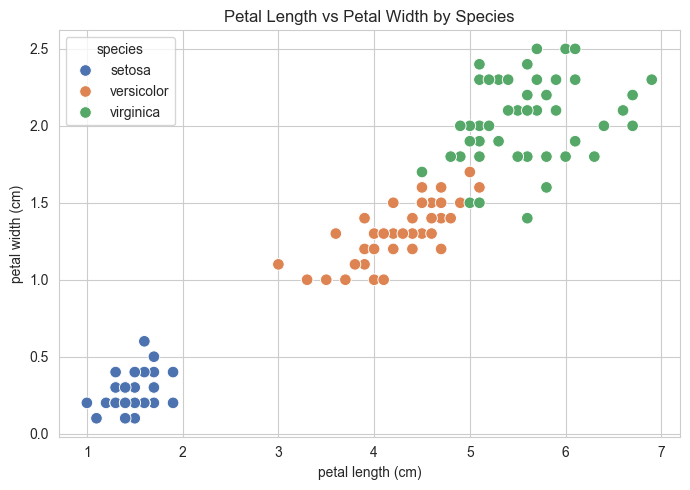

In [5]:
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    palette="deep",
    s=70
)
plt.title("Petal Length vs Petal Width by Species")
plt.tight_layout()
plt.show()

## Step 5: Prepare Data for Training

We split the dataset into a **training set** (80%) and a **test set** (20%).
The model learns from the training set, and we check its performance on the
unseen test set.

In [6]:
X = df[iris.feature_names]
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 120
Testing samples : 30


## Step 6: Train a Machine Learning Model

We use the **K-Nearest Neighbors (KNN)** algorithm — a simple and intuitive
classifier that predicts a flower's species by looking at the species of its
"nearest" neighbors in the training data.

In [7]:
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)
print("Model trained successfully.")

Model trained successfully.


## Step 7: Evaluate the Model

Now we test the model on data it has never seen before, and measure how
accurate its predictions are.

In [8]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



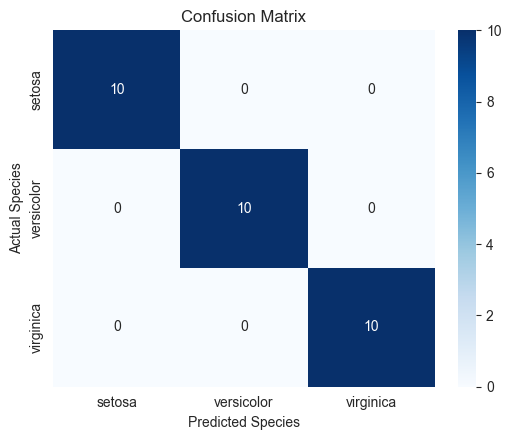

In [ ]:

cm = confusion_matrix(y_test, y_pred, labels=iris.target_names)

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## Step 8: Predict on a New Sample

Finally, let's use the trained model to predict the species of a brand-new
flower measurement that wasn't in the dataset.

In [ ]:

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

prediction = model.predict(new_flower)
print("Predicted species for measurement", new_flower.values.tolist()[0], "->", prediction[0])

Predicted species for measurement [5.1, 3.5, 1.4, 0.2] -> setosa


## Conclusion

In this mini project, we:

1. Loaded and explored the Iris dataset
2. Visualized relationships between features
3. Split the data into training and test sets
4. Trained a K-Nearest Neighbors classifier
5. Evaluated the model's accuracy and confusion matrix
6. Used the trained model to predict the species of a new flower

**Future Scope:** This project can be extended by trying other algorithms
(Decision Trees, SVM, Random Forest), tuning hyperparameters (e.g. the
value of *k* in KNN), and applying the same workflow to larger,
real-world datasets.